In [59]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interactive,interact
from scipy.linalg import null_space

In [60]:
a = 3
b = 2

In [61]:
x = np.linspace(-b,b,a)
y = x
z = x

In [62]:
v = np.zeros((3,a*a))

#Valores do Dóminio.
for ii in range(a):
  for jj in range(a):
    for kk in range(a):

      v[0,jj+ii*a] = x[ii]
      v[1,jj+ii*a] = y[jj]
      v[2,jj+ii*a] = z[kk]
     
display(v)


array([[-2., -2., -2.,  0.,  0.,  0.,  2.,  2.,  2.],
       [-2.,  0.,  2., -2.,  0.,  2., -2.,  0.,  2.],
       [ 2.,  2.,  2.,  2.,  2.,  2.,  2.,  2.,  2.]])

In [63]:
def transfLinear(a11=1, a12=0, a13=0,
                 a21=0, a22=4, a23=0,
                 a31=0, a32=-0, a33=1):
   
    plt.figure()
    plt.axes(projection='3d')
    plt.scatter(v[0,:],v[1,:],v[2,:], alpha=0.5, label='domínio')

    T = np.array( [ [a11,a12,a13],
                   [a21,a22,a23],
                   [a31,a32,a33] ])

    w = T @ v

    limte = 4
    plt.scatter(w[0,:],w[1,:],w[2,:], alpha=0.5, label='imagem')
    plt.xlim(-2*limte,2*limte)
    plt.ylim(-2*limte,2*limte)
    #plt.zlim(-2*limte,2*limte)

    vv = np.array([ [3] , [4] , [5] ] )
    ww = T @ vv

    plt.quiver(vv[0,0,0], vv[1,0,0], vv[2,0,0], angles='xyz', scale_units='xyz', scale=1, label='vv', width = 8e-3, alpha = 5.0)
    plt.quiver(ww[0,0,0], ww[1,0,0], ww[2,0,0], angles='xyz', scale_units='xyz', scale=1, label='ww', width = 4e-3)
    plt.grid(alpha=5.0)

    aVals, aVets = np.linalg.eig(T)
    

    print("aVals =\n", aVals)
    print("aVets =\n", aVets)

    aVets = limte/2 * aVets
    aVetTransf = T @ aVets 

    plt.quiver(aVets[0,0,0], aVets[1,0,0], aVets[0,0,1], angles='xyz', scale_units='xyz', scale=1, label='av1', width = 8e-3, alpha = 5.0, color='red')
    plt.quiver(aVetTransf[0,0,0], aVetTransf[1,0,0], aVetTransf[0,0,1], angles='xyz', scale_units='xyz', scale=1, label='Tav1', width = 4e-3, alpha = 1.0, color='red')

    plt.quiver(aVets[0,1,0], aVets[1,1,0], aVets[1,1,0], angles='xyz', scale_units='xyz', scale=1, label='av2', width = 8e-3, alpha = 5.0, color='blue')
    plt.quiver(aVetTransf[0,1,0], aVetTransf[1,1,0], angles='xyz', scale_units='xyz', scale=1, label='Tav2', width = 4e-3, alpha = 1.0, color='blue')

    plt.quiver(aVets[1,1,1], aVets[1,1,1], aVets[1,1,2], angles='xyz', scale_units='xyz', scale=1, label='av3', width = 8e-3, alpha = 5.0, color='yellow')
    plt.quiver(aVetTransf[1,1,1], aVetTransf[1,1,1], aVetTransf[1,1,2], angles='xyz', scale_units='xyz', scale=1, label='Tav3', width = 4e-3, alpha = 5.0, color='yellow')

    nucleo = null_space(T)
    print("nucleo = \n", nucleo)
    nucleo = nucleo * b/2

    plt.quiver(nucleo[0,0,0], nucleo[1,0,0], nucleo[2,0,0], angles='xyz', scale_units='xyz', scale=1, label='Tav2', width = 8e-3, alpha = 5.0, color='green')


   # plt.legend()

interactive(children=(FloatSlider(value=1.0, description='a11', max=5.0, min=-5.0), FloatSlider(value=0.0, des…

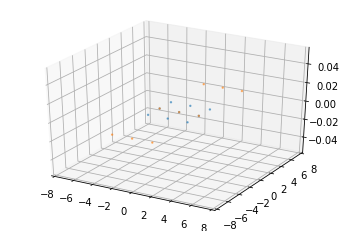

In [64]:
interactive( transfLinear , a11=(-5,5,0.1),a12=(-5,5,0.1),a13=(-5,5,0.1),
                            a21=(-5,5,0.1),a22=(-5,5,0.1),a23=(-5,5,0.1), 
                            a31=(-5,5,0.1),a32=(-5,5,0.1),a33=(-5, 5,0.1))
